# When Outliers Matter: Investigating Gradient-Based Data Selection Under Spurious Correlations

**UCLA CS 260D — Final Project | Fall 2026**

## 6. Experiment 5: Group Distributionally Robust Optimization (Group DRO)

### 6.1 Introduction

Empirical Risk Minimization (ERM) minimizes average loss and can therefore favor the large CelebA groups while nearly ignoring the rare Blond / Male group. Group DRO instead minimizes a dynamically reweighted combination of the four group losses. Groups with larger loss receive more weight through an exponentiated-gradient update.

This notebook follows the shared project protocol: frozen ImageNet ResNet-18 features, a `Linear(512, 2)` classifier, the official train/validation/test splits, Adam, and evaluation with overall and worst-group accuracy. Unlike ERM, EPIC-inspired filtering, JTT, and random filtering, Group DRO uses group labels during training.

For a minibatch with present groups $\mathcal{G}_B$, the update is

$$q_g \leftarrow \frac{q_g \exp(\eta \ell_g)}{\sum_j q_j \exp(\eta \ell_j)}, \qquad L_{\mathrm{DRO}} = \frac{\sum_{g \in \mathcal{G}_B} q_g \ell_g}{\sum_{g \in \mathcal{G}_B} q_g}.$$

The denominator in the minibatch objective keeps the gradient scale stable if a rare group is absent. Log-space updates prevent numerical overflow. The best checkpoint is selected by validation worst-group accuracy (with worst-group loss as a tie-breaker); the test split is used only after model selection.

### 6.2 Environment and Configuration

Run `explore_celeba.ipynb` first to prepare the CelebA metadata. Then run this notebook from the repository root. Feature extraction uses the same frozen ImageNet ResNet-18 and image preprocessing as ERM. The first extraction needs the pretrained weights, which Torchvision downloads if they are missing locally.

In [1]:
# ============================================================
# 6.2 Environment and configuration
# ============================================================

import copy
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


FEATURE_DIR = Path("data/processed/features")
MODEL_DIR = Path("results/models")
METRICS_DIR = Path("results/metrics")
FIGURE_DIR = Path("results/figures")

for directory in (MODEL_DIR, METRICS_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

SEED = 42
EVAL_SEEDS = [42, 123, 2026]
N_GROUPS = 4
FEATURE_DIM = 512
BATCH_SIZE = 512
EVAL_BATCH_SIZE = 4096
EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
GROUP_DRO_STEP_SIZES = (1e-2, 1e-3, 1e-1)

GROUP_NAMES = {
    0: "Non-blond / Non-male",
    1: "Non-blond / Male",
    2: "Blond / Non-male",
    3: "Blond / Male",
}

set_seed(SEED)

print("=" * 55)
print("CelebA Group DRO — Environment")
print("=" * 55)
print(f"PyTorch: {torch.__version__}")
print(f"Device: {device}")
print(f"Seeds: {EVAL_SEEDS}")
print(f"Epochs: {EPOCHS} | Batch size: {BATCH_SIZE}")
print(f"LR: {LEARNING_RATE} | Weight decay: {WEIGHT_DECAY}")
print(f"Group DRO step sizes: {GROUP_DRO_STEP_SIZES}")

CelebA Group DRO — Environment
PyTorch: 2.15.0
Device: mps
Seeds: [42, 123, 2026]
Epochs: 20 | Batch size: 512
LR: 0.001 | Weight decay: 0.0001
Group DRO step sizes: (0.01, 0.001, 0.1)


### 6.3 Prepare Frozen ResNet-18 Features

Use the metadata and official partitions prepared by Explore. Reuse any compatible ERM feature arrays already present. For a missing split, extract features in metadata order and keep them in memory. The test split is prepared after validation-based model selection.

In [2]:
# ============================================================
# 6.3 Prepare frozen ResNet-18 features
# ============================================================

from PIL import Image
from torch.utils.data import Dataset
from torchvision.models import ResNet18_Weights, resnet18

METADATA_PATH = Path("data/processed/celeba_metadata.csv")
IMAGE_DIR = Path("data/celeba/img_align_celeba")
SPLITS = {"train": (0, 162770), "val": (1, 19867), "test": (2, 19962)}
EXTRACTION_BATCH_SIZE = 64

if not METADATA_PATH.is_file():
    raise FileNotFoundError(f"Missing {METADATA_PATH}. Run explore_celeba.ipynb first.")
metadata = pd.read_csv(METADATA_PATH)
backbone = None
transform = None
preparation_seconds = {}


class CelebAImages(Dataset):
    def __init__(self, filenames, transform):
        self.filenames = filenames
        self.transform = transform

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, index):
        with Image.open(IMAGE_DIR / self.filenames[index]) as image:
            return self.transform(image.convert("RGB"))


def extract_features(filenames):
    global backbone, transform
    if not IMAGE_DIR.is_dir():
        raise FileNotFoundError(f"Missing CelebA images at {IMAGE_DIR}.")
    if backbone is None:
        weights = ResNet18_Weights.DEFAULT
        backbone = resnet18(weights=weights)
        backbone.fc = nn.Identity()
        backbone = backbone.requires_grad_(False).to(device).eval()
        transform = weights.transforms()

    loader = DataLoader(
        CelebAImages(filenames, transform),
        batch_size=EXTRACTION_BATCH_SIZE, shuffle=False, num_workers=0,
    )
    features = np.empty((len(filenames), FEATURE_DIM), dtype=np.float32)
    offset = 0
    with torch.inference_mode():
        for batch_index, images in enumerate(loader, start=1):
            batch = backbone(images.to(device)).cpu().numpy()
            end = offset + len(batch)
            features[offset:end] = batch
            offset = end
            if batch_index % 250 == 0 or offset == len(filenames):
                print(f"  Extracted {offset:,}/{len(filenames):,} features", flush=True)
    return features


def load_split(split):
    start = time.perf_counter()
    split_id, expected_count = SPLITS[split]
    rows = metadata.loc[metadata["split"] == split_id]
    labels = rows["label"].to_numpy(dtype=np.int64)
    groups = rows["group"].to_numpy(dtype=np.int64)
    if (len(rows) != expected_count or not rows["filename"].is_unique
            or set(np.unique(groups)) != set(range(N_GROUPS))
            or not np.array_equal(groups // 2, labels)):
        raise ValueError(f"Unexpected CelebA metadata for {split}. Rerun Explore.")

    feature_path = FEATURE_DIR / f"{split}_features.npy"
    label_path = FEATURE_DIR / f"{split}_labels.npy"
    group_path = FEATURE_DIR / f"{split}_groups.npy"
    features = None
    if all(path.is_file() for path in (feature_path, label_path, group_path)):
        cached = np.load(feature_path, mmap_mode="r")
        if (cached.shape == (expected_count, FEATURE_DIM)
                and np.array_equal(np.load(label_path), labels)
                and np.array_equal(np.load(group_path), groups)):
            features = np.array(cached, dtype=np.float32, copy=True)

    source = "ERM feature cache"
    if features is None:
        source = "frozen ResNet-18"
        print(f"{split}: extracting features", flush=True)
        features = extract_features(rows["filename"].to_list())
    preparation_seconds[split] = time.perf_counter() - start
    print(f"{split}: {features.shape} from {source} ({preparation_seconds[split]:.1f} s)")
    return features, labels, groups


X_train, y_train, g_train = load_split("train")
X_val, y_val, g_val = load_split("val")

train: extracting features
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/jerry/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 94.3MB/s]


  Extracted 16,000/162,770 features
  Extracted 32,000/162,770 features
  Extracted 48,000/162,770 features
  Extracted 64,000/162,770 features
  Extracted 80,000/162,770 features
  Extracted 96,000/162,770 features
  Extracted 112,000/162,770 features
  Extracted 128,000/162,770 features
  Extracted 144,000/162,770 features
  Extracted 160,000/162,770 features
  Extracted 162,770/162,770 features
train: (162770, 512) from frozen ResNet-18 (351.4 s)
val: extracting features
  Extracted 16,000/19,867 features
  Extracted 19,867/19,867 features
val: (19867, 512) from frozen ResNet-18 (41.8 s)


### 6.4 Evaluation and Group DRO Training

Each minibatch computes one mean cross-entropy loss per present group. The adversarial weights are updated from detached losses, then the weighted robust loss is backpropagated through the classifier. Validation reports overall accuracy, per-group accuracy, worst-group accuracy, average loss, and maximum group loss.

In [4]:
# ============================================================
# 6.4 Evaluation and Group DRO training
# ============================================================

def evaluate(model, X, y, groups):
    model.eval()
    predictions = []
    losses = []
    criterion = nn.CrossEntropyLoss(reduction="none")

    with torch.inference_mode():
        for start in range(0, len(X), EVAL_BATCH_SIZE):
            end = start + EVAL_BATCH_SIZE
            features = torch.from_numpy(X[start:end]).to(device)
            labels = torch.from_numpy(y[start:end]).long().to(device)
            logits = model(features)
            predictions.append(logits.argmax(dim=1).cpu().numpy())
            losses.append(criterion(logits, labels).cpu().numpy())

    predictions = np.concatenate(predictions)
    losses = np.concatenate(losses)
    group_accuracies = {}
    group_losses = {}

    for group_id in range(N_GROUPS):
        mask = groups == group_id
        if not mask.any():
            raise ValueError(f"Evaluation split has no examples from group {group_id}.")
        group_accuracies[group_id] = float(100 * (predictions[mask] == y[mask]).mean())
        group_losses[group_id] = float(losses[mask].mean())

    worst_group = min(group_accuracies, key=group_accuracies.get)
    return {
        "overall_accuracy": float(100 * (predictions == y).mean()),
        "average_loss": float(losses.mean()),
        "worst_group_accuracy": group_accuracies[worst_group],
        "worst_group": int(worst_group),
        "max_group_loss": max(group_losses.values()),
        "group_accuracies": group_accuracies,
        "group_losses": group_losses,
    }


def train_group_dro(seed, step_size):
    set_seed(seed)

    model = nn.Linear(FEATURE_DIM, 2).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    criterion = nn.CrossEntropyLoss(reduction="none")

    train_dataset = TensorDataset(
        torch.from_numpy(X_train),
        torch.from_numpy(y_train).long(),
        torch.from_numpy(g_train).long(),
    )
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )

    # Uniform initialization in log space.
    log_group_weights = torch.full(
        (N_GROUPS,), -np.log(N_GROUPS), dtype=torch.float32, device=device
    )

    history = []
    best_state = None
    best_epoch = 0
    best_worst_group_accuracy = -float("inf")
    best_max_group_loss = float("inf")

    for epoch in range(EPOCHS):
        model.train()
        robust_loss_sum = 0.0
        group_loss_sums = torch.zeros(N_GROUPS, dtype=torch.float64)
        group_counts = torch.zeros(N_GROUPS, dtype=torch.long)

        for features, labels, groups in train_loader:
            features = features.to(device)
            labels = labels.to(device)
            groups = groups.to(device)

            optimizer.zero_grad()
            example_losses = criterion(model(features), labels)
            group_losses = torch.zeros(N_GROUPS, device=device)
            present = torch.zeros(N_GROUPS, dtype=torch.bool, device=device)

            for group_id in range(N_GROUPS):
                mask = groups == group_id
                if mask.any():
                    present[group_id] = True
                    group_losses[group_id] = example_losses[mask].mean()
                    group_loss_sums[group_id] += example_losses[mask].detach().sum().cpu().double()
                    group_counts[group_id] += mask.sum().cpu()

            # Exponentiated-gradient ascent on the group distribution.
            with torch.no_grad():
                log_group_weights[present] += step_size * group_losses[present].detach()
                log_group_weights -= torch.logsumexp(log_group_weights, dim=0)

            batch_weights = torch.softmax(log_group_weights[present], dim=0)
            robust_loss = (batch_weights * group_losses[present]).sum()

            robust_loss.backward()
            optimizer.step()
            robust_loss_sum += robust_loss.item() * len(labels)

        if not torch.all(group_counts > 0):
            raise RuntimeError("At least one training group was not observed in this epoch.")

        train_group_losses = (group_loss_sums / group_counts.double()).numpy()
        val_result = evaluate(model, X_val, y_val, g_val)
        current_weights = log_group_weights.exp().detach().cpu().numpy()

        row = {
            "epoch": epoch + 1,
            "train_robust_loss": robust_loss_sum / len(train_dataset),
            "val_average_loss": val_result["average_loss"],
            "val_max_group_loss": val_result["max_group_loss"],
            "val_overall_accuracy": val_result["overall_accuracy"],
            "val_worst_group_accuracy": val_result["worst_group_accuracy"],
        }
        for group_id in range(N_GROUPS):
            row[f"train_g{group_id}_loss"] = float(train_group_losses[group_id])
            row[f"q_g{group_id}"] = float(current_weights[group_id])
        history.append(row)

        # Group-aware model selection; test data is never consulted.
        wga = val_result["worst_group_accuracy"]
        max_group_loss = val_result["max_group_loss"]
        improved = (wga > best_worst_group_accuracy + 1e-12) or (
            abs(wga - best_worst_group_accuracy) <= 1e-12
            and max_group_loss < best_max_group_loss
        )
        if improved:
            best_worst_group_accuracy = wga
            best_max_group_loss = max_group_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Seed {seed} | Epoch {epoch + 1:02d}/{EPOCHS} | "
            f"Robust loss {row['train_robust_loss']:.4f} | "
            f"Val {val_result['overall_accuracy']:.2f}% | "
            f"Val WGA {wga:.2f}% | "
            f"q={np.round(current_weights, 3)}",
            flush=True,
        )

    if best_state is None:
        raise RuntimeError("Training did not produce a checkpoint.")

    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history), best_epoch

### 6.5 Validation Tuning and Multi-Seed Evaluation

Tune the Group DRO step size on seed 42 using validation worst-group accuracy and maximum group loss. Reuse the selected seed-42 run and train with the selected step size for seeds 123 and 2026. Once all checkpoints are fixed, evaluate them on the held-out test split. Compare validation mean and sample standard deviation with the tracked ERM, Random, and Isolation results from the EPIC 10% filtering experiment when available.

In [5]:
# ============================================================
# 6.5 Multi-seed training and final evaluation
# ============================================================

run_rows = []
group_rows = []
history_frames = []
trained_models = {}
best_epochs = {}

search_rows = []
selected_run = None
best_score = (-float("inf"), -float("inf"))
search_start = time.perf_counter()
for step_size in GROUP_DRO_STEP_SIZES:
    print(f"\nValidation search | step size: {step_size:g}")
    start = time.perf_counter()
    model, history, best_epoch = train_group_dro(SEED, step_size)
    seconds = time.perf_counter() - start
    val = history.iloc[best_epoch - 1]
    search_rows.append({
        "step_size": step_size, "seed": SEED, "best_epoch": best_epoch,
        "val_overall_accuracy": val["val_overall_accuracy"],
        "val_worst_group_accuracy": val["val_worst_group_accuracy"],
        "val_max_group_loss": val["val_max_group_loss"],
        "training_time_seconds": seconds,
    })
    score = (val["val_worst_group_accuracy"], -val["val_max_group_loss"])
    if score > best_score:
        best_score = score
        selected_step_size = step_size
        selected_run = (model, history, best_epoch, seconds)

search_seconds = time.perf_counter() - search_start
search_df = pd.DataFrame(search_rows)
print(search_df.round(4).to_string(index=False))
print(f"Selected step size: {selected_step_size:g}")
training_times = {}

for seed in EVAL_SEEDS:
    if seed == SEED:
        model, history, best_epoch, training_seconds = selected_run
    else:
        start = time.perf_counter()
        model, history, best_epoch = train_group_dro(seed, selected_step_size)
        training_seconds = time.perf_counter() - start

    history.insert(0, "seed", seed)
    history_frames.append(history)
    trained_models[seed] = model
    best_epochs[seed] = best_epoch
    training_times[seed] = training_seconds

X_test, y_test, g_test = load_split("test")

for seed, model in trained_models.items():
    for split, (X, y, groups) in {
        "val": (X_val, y_val, g_val),
        "test": (X_test, y_test, g_test),
    }.items():
        result = evaluate(model, X, y, groups)
        run_rows.append({
            "seed": seed,
            "split": split,
            "best_epoch": best_epochs[seed],
            "overall_accuracy": result["overall_accuracy"],
            "worst_group_accuracy": result["worst_group_accuracy"],
            "worst_group": result["worst_group"],
            "average_loss": result["average_loss"],
            "max_group_loss": result["max_group_loss"],
            "training_time_seconds": training_times[seed],
        })
        for group_id in range(N_GROUPS):
            group_rows.append({
                "seed": seed,
                "split": split,
                "group": group_id,
                "description": GROUP_NAMES[group_id],
                "samples": int((groups == group_id).sum()),
                "accuracy": result["group_accuracies"][group_id],
                "loss": result["group_losses"][group_id],
            })

history_df = pd.concat(history_frames, ignore_index=True)
runs_df = pd.DataFrame(run_rows)
group_results_df = pd.DataFrame(group_rows)
total_training_seconds = sum(training_times.values())

summary_df = (
    runs_df.groupby("split")
    [["overall_accuracy", "worst_group_accuracy", "training_time_seconds"]]
    .agg(["mean", "std"])
    .round(2)
)

print("\nGroup DRO runs")
print(runs_df.round(2).to_string(index=False))
print("\nMean ± std over seeds")
print(summary_df.to_string())
print(f"\nSelected runs: {total_training_seconds:.1f} s | Validation search: {search_seconds:.1f} s")

val_runs = runs_df.loc[runs_df["split"] == "val"]
comparison_df = pd.DataFrame([{
    "Method": "Group DRO",
    "Overall_Mean": val_runs["overall_accuracy"].mean(),
    "Overall_Std": val_runs["overall_accuracy"].std(),
    "Worst_Mean": val_runs["worst_group_accuracy"].mean(),
    "Worst_Std": val_runs["worst_group_accuracy"].std(),
}])
reference_path = METRICS_DIR / "epic_multiseed_10pct_summary.csv"
if reference_path.is_file():
    reference = pd.read_csv(reference_path)
    comparison_df = pd.concat([reference, comparison_df], ignore_index=True)

print("\nValidation comparison across seeds (accuracy in %)")
print(comparison_df.round(2).to_string(index=False))


Validation search | step size: 0.01


/var/folders/y5/hw34p2w94vd8hqcjryr8q8qc0000gn/T/ipykernel_27723/419002560.py:55: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:214.)
  torch.from_numpy(y_train).long(),


Seed 42 | Epoch 01/20 | Robust loss 0.4073 | Val 83.65% | Val WGA 81.14% | q=[0.259 0.251 0.192 0.298]
Seed 42 | Epoch 02/20 | Robust loss 0.3340 | Val 87.38% | Val WGA 76.37% | q=[0.253 0.267 0.157 0.323]
Seed 42 | Epoch 03/20 | Robust loss 0.3290 | Val 89.57% | Val WGA 71.43% | q=[0.241 0.283 0.131 0.345]
Seed 42 | Epoch 04/20 | Robust loss 0.3262 | Val 85.82% | Val WGA 84.07% | q=[0.227 0.295 0.114 0.365]
Seed 42 | Epoch 05/20 | Robust loss 0.3117 | Val 89.88% | Val WGA 73.08% | q=[0.217 0.309 0.106 0.368]
Seed 42 | Epoch 06/20 | Robust loss 0.3108 | Val 87.83% | Val WGA 79.12% | q=[0.209 0.315 0.1   0.376]
Seed 42 | Epoch 07/20 | Robust loss 0.3173 | Val 85.27% | Val WGA 83.83% | q=[0.2   0.322 0.09  0.387]
Seed 42 | Epoch 08/20 | Robust loss 0.3154 | Val 85.17% | Val WGA 82.46% | q=[0.192 0.331 0.083 0.395]
Seed 42 | Epoch 09/20 | Robust loss 0.3078 | Val 83.06% | Val WGA 81.07% | q=[0.186 0.341 0.08  0.394]
Seed 42 | Epoch 10/20 | Robust loss 0.3098 | Val 85.10% | Val WGA 83.64% 

### 6.6 Training Dynamics and Group-Wise Results

Inspect the seed-42 robust objective, validation worst-group accuracy, and adversarial group weights. Then visualize validation accuracy for all four groups, averaged over the three seeds.

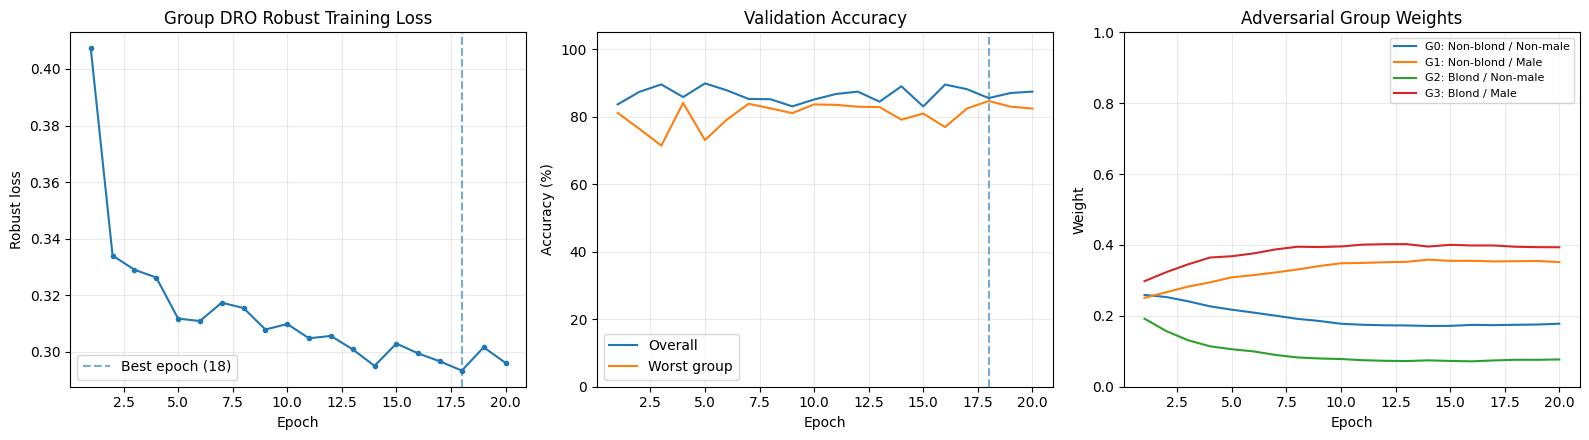

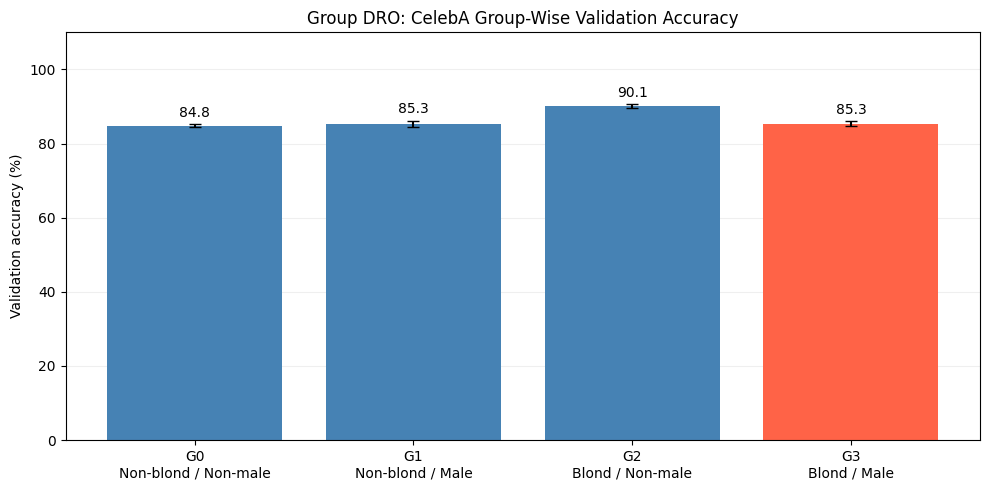

Training curves saved to: results/figures/groupdro_training_curves.png
Group comparison saved to: results/figures/groupdro_group_accuracy.png


In [6]:
# ============================================================
# 6.6 Visualize training dynamics and group accuracies
# ============================================================

seed_history = history_df[history_df["seed"] == SEED]
epochs = seed_history["epoch"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(epochs, seed_history["train_robust_loss"], marker="o", markersize=3)
axes[0].axvline(best_epochs[SEED], linestyle="--", alpha=0.6,
                label=f"Best epoch ({best_epochs[SEED]})")
axes[0].set_title("Group DRO Robust Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Robust loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(epochs, seed_history["val_overall_accuracy"], label="Overall")
axes[1].plot(epochs, seed_history["val_worst_group_accuracy"], label="Worst group")
axes[1].axvline(best_epochs[SEED], linestyle="--", alpha=0.6)
axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(0, 105)
axes[1].legend()
axes[1].grid(alpha=0.25)

for group_id in range(N_GROUPS):
    axes[2].plot(epochs, seed_history[f"q_g{group_id}"],
                 label=f"G{group_id}: {GROUP_NAMES[group_id]}")
axes[2].set_title("Adversarial Group Weights")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Weight")
axes[2].set_ylim(0, 1)
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.25)

plt.tight_layout()
training_figure_path = FIGURE_DIR / "groupdro_training_curves.png"
fig.savefig(training_figure_path, dpi=300, bbox_inches="tight")
plt.show()

val_group_summary = (
    group_results_df[group_results_df["split"] == "val"]
    .groupby("group")["accuracy"]
    .agg(["mean", "std"])
)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(N_GROUPS)
bars = ax.bar(
    x, val_group_summary["mean"], yerr=val_group_summary["std"],
    capsize=4, color=["steelblue", "steelblue", "steelblue", "tomato"],
)
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set_xticks(x)
ax.set_xticklabels([f"G{k}\n{GROUP_NAMES[k]}" for k in range(N_GROUPS)])
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("Group DRO: CelebA Group-Wise Validation Accuracy")
ax.set_ylim(0, 110)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
group_figure_path = FIGURE_DIR / "groupdro_group_accuracy.png"
fig.savefig(group_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Training curves saved to: {training_figure_path}")
print(f"Group comparison saved to: {group_figure_path}")

### 6.7 Save Group DRO Results

Save the validation search, comparison table, multi-seed metrics, per-group results, full learning curves, seed-42 checkpoint, and experiment summary under `results/`.

In [7]:
# ============================================================
# 6.7 Save Group DRO results
# ============================================================

history_path = METRICS_DIR / "groupdro_celeba_history.csv"
runs_path = METRICS_DIR / "groupdro_multiseed.csv"
groups_path = METRICS_DIR / "groupdro_group_accuracy.csv"
metrics_path = METRICS_DIR / "groupdro_celeba.json"
checkpoint_path = MODEL_DIR / "groupdro_celeba.pt"
search_path = METRICS_DIR / "groupdro_hparam_search.csv"
comparison_path = METRICS_DIR / "groupdro_validation_comparison.csv"

history_df.to_csv(history_path, index=False)
runs_df.to_csv(runs_path, index=False)
group_results_df.to_csv(groups_path, index=False)
search_df.to_csv(search_path, index=False)
comparison_df.to_csv(comparison_path, index=False)


def summarize_split(split):
    rows = runs_df[runs_df["split"] == split]
    groups = group_results_df[group_results_df["split"] == split]
    return {
        "overall_accuracy_mean": float(rows["overall_accuracy"].mean()),
        "overall_accuracy_std": float(rows["overall_accuracy"].std(ddof=1)),
        "worst_group_accuracy_mean": float(rows["worst_group_accuracy"].mean()),
        "worst_group_accuracy_std": float(rows["worst_group_accuracy"].std(ddof=1)),
        "group_accuracies_mean": {
            str(group_id): float(value)
            for group_id, value in groups.groupby("group")["accuracy"].mean().items()
        },
    }


experiment_results = {
    "experiment": "Group Distributionally Robust Optimization",
    "dataset": "CelebA",
    "target": "Blond_Hair",
    "spurious_attribute": "Male",
    "uses_group_labels": True,
    "feature_extractor": "ImageNet ResNet-18 (frozen)",
    "classifier": "Linear(512, 2)",
    "seeds": EVAL_SEEDS,
    "epochs": EPOCHS,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "batch_size": BATCH_SIZE,
    "group_dro_step_size": selected_step_size,
    "group_dro_step_size_candidates": GROUP_DRO_STEP_SIZES,
    "hyperparameter_selection_seed": SEED,
    "validation_search_seconds": search_seconds,
    "feature_preparation_seconds": preparation_seconds,
    "group_weight_update": "log-space exponentiated gradient",
    "checkpoint_selection": "maximum validation worst-group accuracy; minimum maximum-group loss tie-breaker",
    "best_epochs": {str(seed): int(epoch) for seed, epoch in best_epochs.items()},
    "validation": summarize_split("val"),
    "test": summarize_split("test"),
    "training_time_seconds_total": float(total_training_seconds),
}

with open(metrics_path, "w") as file:
    json.dump(experiment_results, file, indent=4)

torch.save({
    "model_state_dict": trained_models[SEED].state_dict(),
    "seed": SEED,
    "best_epoch": best_epochs[SEED],
    "input_dim": FEATURE_DIM,
    "num_classes": 2,
    "group_dro_step_size": selected_step_size,
    "feature_extractor": "ImageNet ResNet-18",
    "feature_extractor_frozen": True,
}, checkpoint_path)

print("Saved:")
for path in [history_path, runs_path, groups_path, metrics_path,
             search_path, comparison_path, training_figure_path,
             group_figure_path, checkpoint_path]:
    print(f"  {path}")

Saved:
  results/metrics/groupdro_celeba_history.csv
  results/metrics/groupdro_multiseed.csv
  results/metrics/groupdro_group_accuracy.csv
  results/metrics/groupdro_celeba.json
  results/metrics/groupdro_hparam_search.csv
  results/metrics/groupdro_validation_comparison.csv
  results/figures/groupdro_training_curves.png
  results/figures/groupdro_group_accuracy.png
  results/models/groupdro_celeba.pt


### 6.8 Interpretation Guide

Check whether Group DRO improves worst-group accuracy over ERM and the two filtering methods in the validation table. Inspect all four groups and note any change in overall accuracy. The test table reports the held-out performance of Group DRO.

Important caveats:

1. Group DRO has access to training group labels, so it is not directly comparable to the group-agnostic filtering methods on supervision requirements.
2. The backbone is ImageNet-pretrained and frozen for every project method. The experiment therefore tests robust last-layer training, not end-to-end Group DRO fine-tuning.
3. The adversarial weights are path-dependent minibatch estimates. Multi-seed reporting is necessary because the rare G3 group contributes only a few examples to a typical batch.
4. Step size and checkpoints are selected on validation data. The tracked ERM and filtering references were originally selected by minimum validation loss, so checkpoint criteria differ across methods.